In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("dataset.csv")

df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [3]:
print("Dataset Shape:", df.shape)
print("Total Rows:", df.shape[0])
print("Total Columns:", df.shape[1])

Dataset Shape: (8790, 10)
Total Rows: 8790
Total Columns: 10


In [ ]:
# Check missing values in each column
print(df.isnull().sum())
# Total missing values
print("\nTotal Missing Values:", df.isnull().sum().sum())

show_id         0
type            0
title           0
director        0
country         0
date_added      0
release_year    0
rating          0
duration        0
listed_in       0
dtype: int64

Total Missing Values: 0


In [5]:
# Check duplicate records
duplicate_count = df.duplicated().sum()
print("Total Duplicate Records:", duplicate_count)

Total Duplicate Records: 0


In [6]:
# Count each content type
type_counts = df['type'].value_counts()

print(type_counts)

type
Movie      6126
TV Show    2664
Name: count, dtype: int64


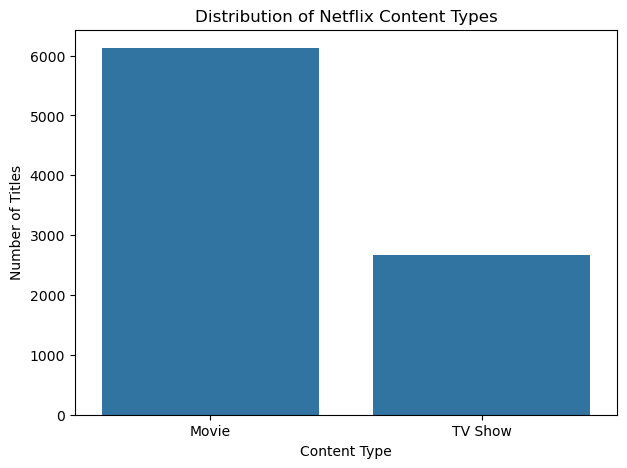

In [7]:
plt.figure(figsize=(7,5))
sns.countplot(data=df, x='type')
plt.title('Distribution of Netflix Content Types')
plt.xlabel('Content Type')
plt.ylabel('Number of Titles')
plt.show()

In [8]:
print("Earliest Release Year:", df['release_year'].min())
print("Latest Release Year:", df['release_year'].max())
print("\nContent Released Per Year:")
print(df['release_year'].value_counts().sort_index().tail(10))

Earliest Release Year: 1925
Latest Release Year: 2021

Content Released Per Year:
release_year
2012     236
2013     286
2014     352
2015     555
2016     901
2017    1030
2018    1146
2019    1030
2020     953
2021     592
Name: count, dtype: int64


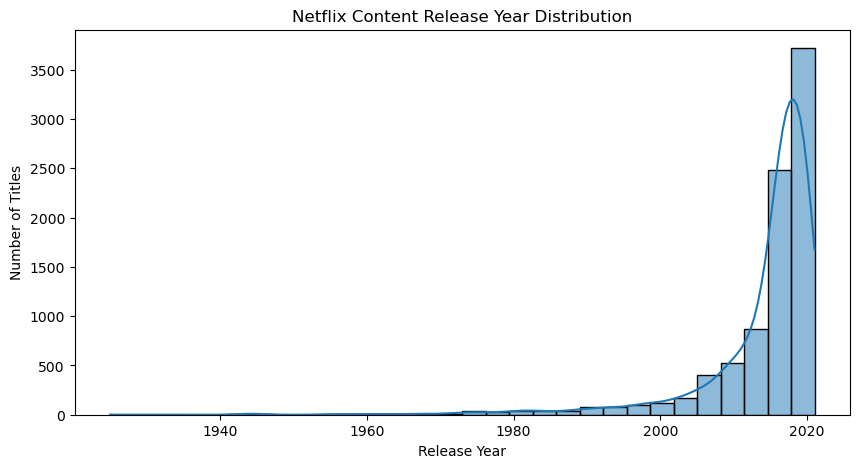

In [9]:
plt.figure(figsize=(10,5))
sns.histplot(data=df, x='release_year', bins=30, kde=True)
plt.title('Netflix Content Release Year Distribution')
plt.xlabel('Release Year')
plt.ylabel('Number of Titles')
plt.show()

In [10]:
print("Rating Categories:")
print(df['rating'].value_counts())

Rating Categories:
rating
TV-MA       3205
TV-14       2157
TV-PG        861
R            799
PG-13        490
TV-Y7        333
TV-Y         306
PG           287
TV-G         220
NR            79
G             41
TV-Y7-FV       6
NC-17          3
UR             3
Name: count, dtype: int64


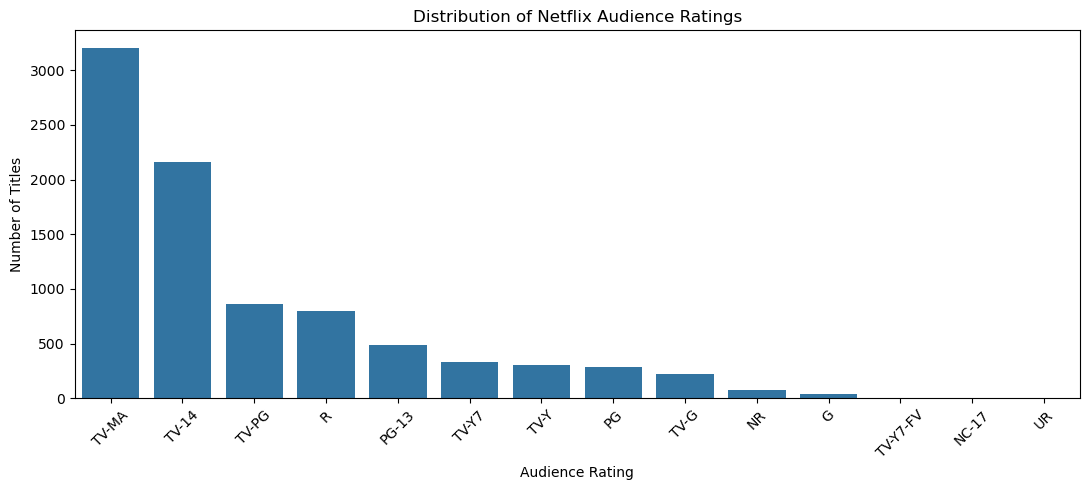

In [11]:
plt.figure(figsize=(11,5))
sns.countplot(data=df, x='rating', order=df['rating'].value_counts().index)
plt.title('Distribution of Netflix Audience Ratings')
plt.xlabel('Audience Rating')
plt.ylabel('Number of Titles')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

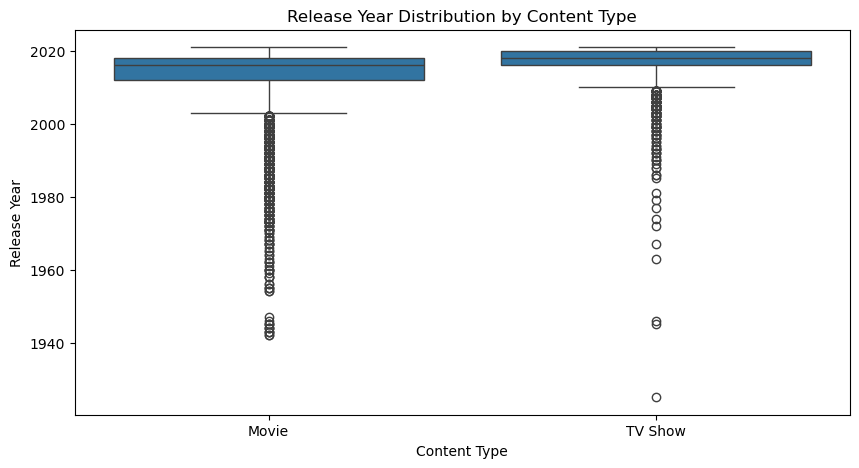

In [12]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x='type', y='release_year')
plt.title('Release Year Distribution by Content Type')
plt.xlabel('Content Type')
plt.ylabel('Release Year')
plt.show()

In [13]:
print("Sample Movie Durations:")
print(df[df['type']=='Movie']['duration'].head(10))
print("\nSample TV Show Durations:")
print(df[df['type']=='TV Show']['duration'].head(10))

Sample Movie Durations:
0      90 min
3      91 min
4     125 min
6     104 min
7      87 min
8     127 min
9      76 min
10     76 min
11     71 min
12    131 min
Name: duration, dtype: object

Sample TV Show Durations:
1      1 Season
2      1 Season
5     9 Seasons
17     1 Season
18     1 Season
20     1 Season
21     1 Season
22     1 Season
24     1 Season
27     1 Season
Name: duration, dtype: object


In [14]:
country_counts = df['country'].value_counts().head(10)
print(country_counts)

country
United States     3240
India             1057
United Kingdom     638
Pakistan           421
Not Given          287
Canada             271
Japan              259
South Korea        214
France             213
Spain              182
Name: count, dtype: int64


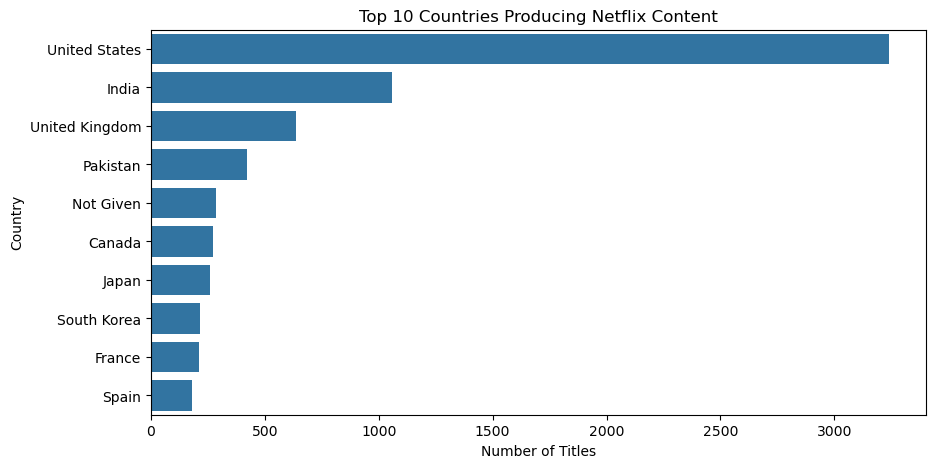

In [15]:
plt.figure(figsize=(10,5))
sns.barplot(x=country_counts.values, y=country_counts.index)
plt.title('Top 10 Countries Producing Netflix Content')
plt.xlabel('Number of Titles')
plt.ylabel('Country')
plt.show()

In [16]:
genre_counts = df['listed_in'].str.split(', ').explode().value_counts().head(10)
print(genre_counts)

listed_in
International Movies        2752
Dramas                      2426
Comedies                    1674
International TV Shows      1349
Documentaries                869
Action & Adventure           859
TV Dramas                    762
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64


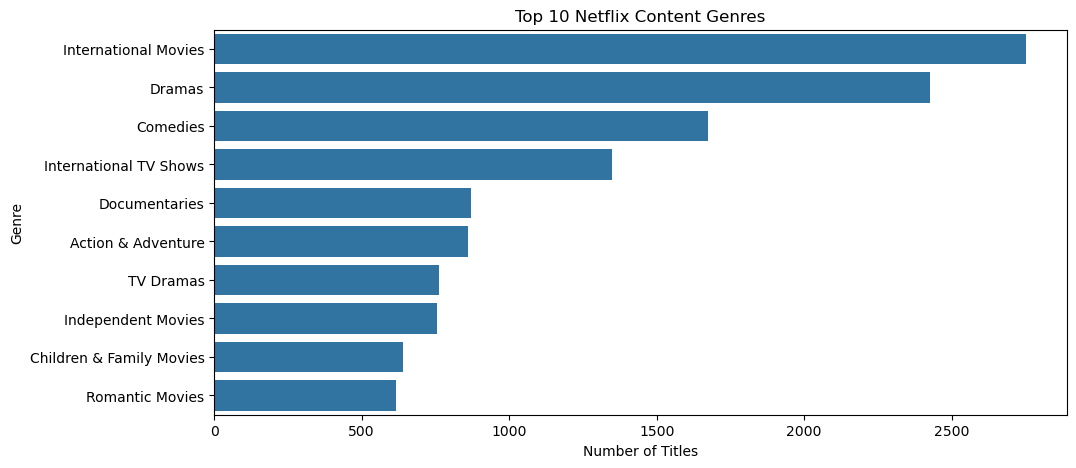

In [17]:
plt.figure(figsize=(11,5))
sns.barplot(x=genre_counts.values, y=genre_counts.index)
plt.title('Top 10 Netflix Content Genres')
plt.xlabel('Number of Titles')
plt.ylabel('Genre')
plt.show()

In [18]:
print("Available Features:")
for col in df.columns:
    print(col)

Available Features:
show_id
type
title
director
country
date_added
release_year
rating
duration
listed_in


In [19]:
X = df[['release_year', 'country', 'rating', 'listed_in']]
y = df['type']
print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)
print("\nInput Features:")
print(X.head())
print("\nTarget:")
print(y.head())

Input Features Shape: (8790, 4)
Target Shape: (8790,)

Input Features:
   release_year        country rating  \
0          2020  United States  PG-13   
1          2021         France  TV-MA   
2          2021  United States  TV-MA   
3          2021         Brazil  TV-PG   
4          1993  United States  TV-MA   

                                           listed_in  
0                                      Documentaries  
1  Crime TV Shows, International TV Shows, TV Act...  
2                 TV Dramas, TV Horror, TV Mysteries  
3                 Children & Family Movies, Comedies  
4   Dramas, Independent Movies, International Movies  

Target:
0      Movie
1    TV Show
2    TV Show
3      Movie
4      Movie
Name: type, dtype: object


In [20]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)
print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (7032, 4)
Testing Features: (1758, 4)
Training Target: (7032,)
Testing Target: (1758,)


In [21]:
print("Unique Countries:", X_train['country'].nunique())
print("Unique Ratings:", X_train['rating'].nunique())
print("Unique Genre Combinations:", X_train['listed_in'].nunique())

Unique Countries: 79
Unique Ratings: 14
Unique Genre Combinations: 490


In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.pipeline import Pipeline

In [23]:
preprocessor = ColumnTransformer(transformers=[
    ('country', OneHotEncoder(handle_unknown='ignore'), ['country']),
    ('rating', OneHotEncoder(handle_unknown='ignore'), ['rating']),
    ('genre', CountVectorizer(), 'listed_in'),
    ('year', 'passthrough', ['release_year'])
])
print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [24]:
X_train_processed = preprocessor.fit_transform(X_train)
print("Training Data Shape:", X_train_processed.shape)
print("Preprocessing completed successfully!")

Training Data Shape: (7032, 139)
Preprocessing completed successfully!


In [25]:
X_test_processed = preprocessor.transform(X_test)
print("Testing Data Shape:", X_test_processed.shape)
print("Testing preprocessing completed successfully!")

Testing Data Shape: (1758, 139)
Testing preprocessing completed successfully!


In [26]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [27]:
y_pred_lr = lr_model.predict(X_test_processed)
print("First 10 Predictions:")
print(y_pred_lr[:10])

First 10 Predictions:
['Movie' 'Movie' 'Movie' 'Movie' 'TV Show' 'Movie' 'TV Show' 'Movie'
 'Movie' 'Movie']


In [28]:
from sklearn.metrics import accuracy_score

lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 100.0 %


In [29]:
from sklearn.metrics import classification_report, confusion_matrix
print(classification_report(y_test, y_pred_lr))
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

              precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1225
     TV Show       1.00      1.00      1.00       533

    accuracy                           1.00      1758
   macro avg       1.00      1.00      1.00      1758
weighted avg       1.00      1.00      1.00      1758

Confusion Matrix:
[[1225    0]
 [   0  533]]


In [30]:
print("Rating starts with TV:")
print(pd.crosstab(df['rating'].str.startswith('TV-'), df['type']))
print("\nGenre contains TV:")
print(pd.crosstab(df['listed_in'].str.contains('TV', case=False), df['type']))
print("\nGenre contains Movies:")
print(pd.crosstab(df['listed_in'].str.contains('Movies', case=False), df['type']))

Rating starts with TV:
type    Movie  TV Show
rating                
False    1696        6
True     4430     2658

Genre contains TV:
type       Movie  TV Show
listed_in                
False       6126      104
True           0     2560

Genre contains Movies:
type       Movie  TV Show
listed_in                
False       1628     2664
True        4498        0


In [31]:
X = df[['release_year', 'country']]
y = df['type']
print("Input Features:", X.columns.tolist())
print("Input Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features: ['release_year', 'country']
Input Shape: (8790, 2)
Target Shape: (8790,)


In [32]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (7032, 2)
Testing Data: (1758, 2)


In [33]:
preprocessor = ColumnTransformer(transformers=[
    ('country', OneHotEncoder(handle_unknown='ignore'), ['country']),
    ('year', 'passthrough', ['release_year'])
])
print("Updated preprocessing pipeline created!")

Updated preprocessing pipeline created!


In [34]:
X_train_processed = preprocessor.fit_transform(X_train)
print("Training Data Shape:", X_train_processed.shape)

Training Data Shape: (7032, 80)


In [35]:
X_test_processed = preprocessor.transform(X_test)
print("Testing Data Shape:", X_test_processed.shape)

Testing Data Shape: (1758, 80)


In [36]:
lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_processed, y_train)
print("Logistic Regression training completed!")

Logistic Regression training completed!


c:\Users\dhars\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:469: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [37]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_train_processed = X_train_processed.toarray()
X_test_processed = X_test_processed.toarray()
X_train_processed[:, -1] = scaler.fit_transform(X_train_processed[:, -1].reshape(-1, 1)).ravel()
X_test_processed[:, -1] = scaler.transform(X_test_processed[:, -1].reshape(-1, 1)).ravel()
print("Feature scaling completed!")

Feature scaling completed!


In [38]:
lr_model = LogisticRegression(max_iter=3000, random_state=42)
lr_model.fit(X_train_processed, y_train)
print("Logistic Regression training completed successfully!")

Logistic Regression training completed successfully!


In [39]:
y_pred_lr = lr_model.predict(X_test_processed)
lr_accuracy = accuracy_score(y_test, y_pred_lr)
print("Logistic Regression Accuracy:", round(lr_accuracy * 100, 2), "%")

Logistic Regression Accuracy: 76.28 %


In [40]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(max_depth=10, random_state=42)
dt_model.fit(X_train_processed, y_train)
print("Decision Tree training completed!")

Decision Tree training completed!


In [41]:
y_pred_dt = dt_model.predict(X_test_processed)
dt_accuracy = accuracy_score(y_test, y_pred_dt)
print("Decision Tree Accuracy:", round(dt_accuracy * 100, 2), "%")

Decision Tree Accuracy: 76.45 %


In [42]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)
rf_model.fit(X_train_processed, y_train)
print("Random Forest training completed!")

Random Forest training completed!


In [43]:
y_pred_rf = rf_model.predict(X_test_processed)
rf_accuracy = accuracy_score(y_test, y_pred_rf)
print("Random Forest Accuracy:", round(rf_accuracy * 100, 2), "%")

Random Forest Accuracy: 75.82 %


In [44]:
results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Decision Tree', 'Random Forest'],
    'Accuracy': [lr_accuracy, dt_accuracy, rf_accuracy]
})
results['Accuracy (%)'] = (results['Accuracy'] * 100).round(2)
print(results[['Model', 'Accuracy (%)']])

                 Model  Accuracy (%)
0  Logistic Regression         76.28
1        Decision Tree         76.45
2        Random Forest         75.82


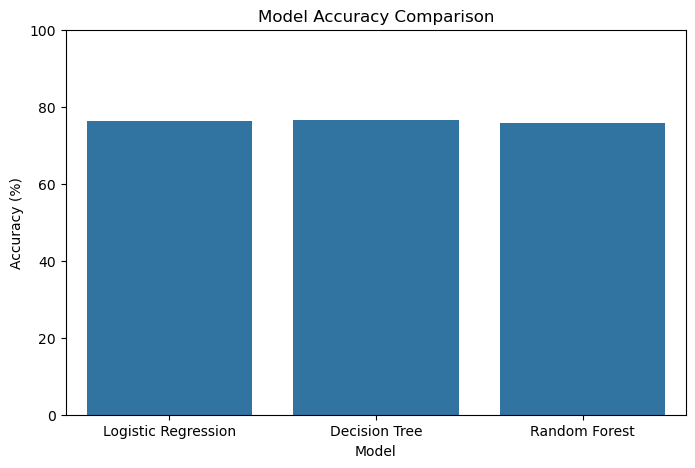

In [45]:
plt.figure(figsize=(8,5))
sns.barplot(data=results, x='Model', y='Accuracy (%)')
plt.title('Model Accuracy Comparison')
plt.ylabel('Accuracy (%)')
plt.ylim(0, 100)
plt.show()

In [46]:
from sklearn.metrics import classification_report
print("LOGISTIC REGRESSION")
print(classification_report(y_test, y_pred_lr))
print("DECISION TREE")
print(classification_report(y_test, y_pred_dt))
print("RANDOM FOREST")
print(classification_report(y_test, y_pred_rf))

LOGISTIC REGRESSION
              precision    recall  f1-score   support

       Movie       0.76      0.96      0.85      1225
     TV Show       0.78      0.30      0.44       533

    accuracy                           0.76      1758
   macro avg       0.77      0.63      0.64      1758
weighted avg       0.77      0.76      0.72      1758

DECISION TREE
              precision    recall  f1-score   support

       Movie       0.77      0.95      0.85      1225
     TV Show       0.74      0.34      0.47       533

    accuracy                           0.76      1758
   macro avg       0.76      0.65      0.66      1758
weighted avg       0.76      0.76      0.73      1758

RANDOM FOREST
              precision    recall  f1-score   support

       Movie       0.75      0.97      0.85      1225
     TV Show       0.81      0.27      0.40       533

    accuracy                           0.76      1758
   macro avg       0.78      0.62      0.62      1758
weighted avg       0.77   

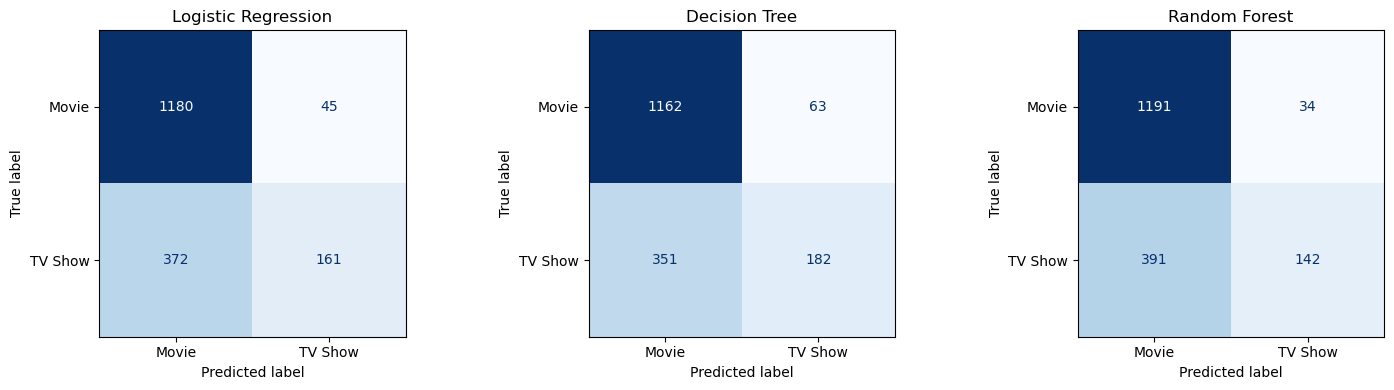

In [47]:
from sklearn.metrics import ConfusionMatrixDisplay
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
models = [(y_pred_lr, 'Logistic Regression'), (y_pred_dt, 'Decision Tree'), (y_pred_rf, 'Random Forest')]
for ax, (pred, name) in zip(axes, models):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(name)
plt.tight_layout()
plt.show()

In [48]:
dt_balanced = DecisionTreeClassifier(max_depth=10, class_weight='balanced', random_state=42)
dt_balanced.fit(X_train_processed, y_train)
print("Balanced Decision Tree training completed!")

Balanced Decision Tree training completed!


In [49]:
y_pred_balanced = dt_balanced.predict(X_test_processed)
balanced_accuracy = accuracy_score(y_test, y_pred_balanced)
print("Balanced Decision Tree Accuracy:", round(balanced_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_balanced))


Balanced Decision Tree Accuracy: 71.1 %

Classification Report:
              precision    recall  f1-score   support

       Movie       0.86      0.70      0.77      1225
     TV Show       0.52      0.74      0.61       533

    accuracy                           0.71      1758
   macro avg       0.69      0.72      0.69      1758
weighted avg       0.76      0.71      0.72      1758



In [50]:
from sklearn.model_selection import GridSearchCV
param_grid = {
    'max_depth': [5, 10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'class_weight': [None, 'balanced']
}
grid_search = GridSearchCV(DecisionTreeClassifier(random_state=42), param_grid, cv=3, scoring='f1_macro', n_jobs=-1)
grid_search.fit(X_train_processed, y_train)
print("Best Parameters:", grid_search.best_params_)
print("Best Cross-Validation F1:", round(grid_search.best_score_, 4))

Best Parameters: {'class_weight': 'balanced', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}
Best Cross-Validation F1: 0.6786


In [51]:
best_dt = grid_search.best_estimator_
best_dt.fit(X_train_processed, y_train)
y_pred_best = best_dt.predict(X_test_processed)
print("Tuned Decision Tree training completed!")

Tuned Decision Tree training completed!


In [52]:
best_accuracy = accuracy_score(y_test, y_pred_best)
print("Tuned Decision Tree Accuracy:", round(best_accuracy * 100, 2), "%")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_best))

Tuned Decision Tree Accuracy: 71.16 %

Classification Report:
              precision    recall  f1-score   support

       Movie       0.86      0.70      0.77      1225
     TV Show       0.52      0.74      0.61       533

    accuracy                           0.71      1758
   macro avg       0.69      0.72      0.69      1758
weighted avg       0.76      0.71      0.72      1758



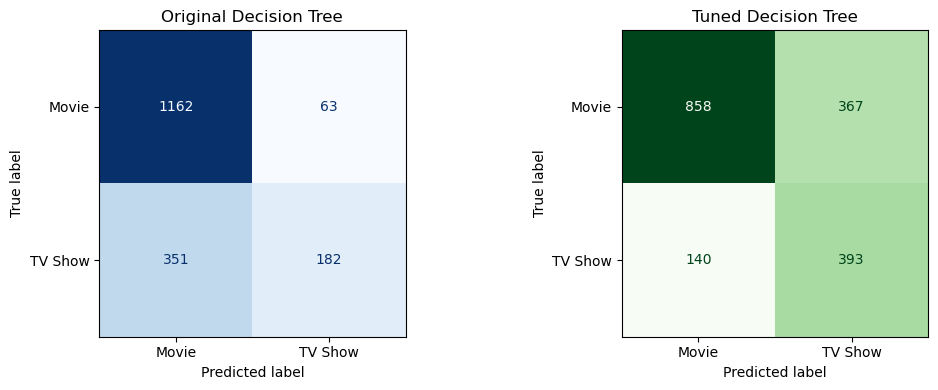

In [53]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_dt, ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Original Decision Tree')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_best, ax=axes[1], cmap='Greens', colorbar=False)
axes[1].set_title('Tuned Decision Tree')
plt.tight_layout()
plt.show()

In [54]:
import os
os.makedirs("models", exist_ok=True)

In [55]:
final_model = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', best_dt)
])
final_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('country',
                                                  OneHotEncoder(handle_unknown='ignore'),
                                                  ['country']),
                                                 ('year', 'passthrough',
                                                  ['release_year'])])),
                ('classifier',
                 DecisionTreeClassifier(class_weight='balanced', max_depth=10,
                                        min_samples_leaf=2,
                                        min_samples_split=10,
                                        random_state=42))])

In [56]:
import joblib
joblib.dump(final_model, "models/netflix_content_type_model.pkl")
print("Model saved successfully!")

Model saved successfully!


In [57]:
loaded_model = joblib.load("models/netflix_content_type_model.pkl")
new_data = pd.DataFrame({
    'release_year': [2020, 2015, 2018],
    'country': ['India', 'United States', 'Japan']
})
predictions = loaded_model.predict(new_data)
for i, prediction in enumerate(predictions):
    print(f"Content {i+1}: {prediction}")

Content 1: Movie
Content 2: Movie
Content 3: TV Show


In [1]:
import sklearn
print(sklearn.__version__)

1.9.1
